In [1]:
import numpy as np
from langchain_ollama import ChatOllama
from rag_flow import RAGFlow
import pandas as pd
from time import perf_counter
import matplotlib.pyplot as plt
import ast


/Users/vilya/Desktop/capstone_project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-11 16:26:06,829 | INFO | No device provided, using mps
2026-10-11 16:26:06,969 | INFO | HTTP Request: HEAD https://huggingface.co/cross-encoder/ms-marco-MiniLM-L6-v2/resolve/main/modules.json "HTTP/1.1 404 Not Found"
2026-10-11 16:26:06,970 | WARNING | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
2026-10-11 16:26:06,972 | INFO | No modules.json found for cross-encoder/ms-marco-MiniLM-L6-v2, initializing a new CrossEncoder model.
2026-10-11 16:26:07,056 | INFO | HTTP Request: GET https://huggingface.co/api/models/cross-encoder/ms-marco-MiniLM-L6-v2 "HTTP/1.1 200 OK"
2026-10-11 16:26:07,144 | INFO | HTTP Request: GE

The goal of this file is to evaluate the quality of the retrieval. The metrics I am going to use:

- Mean Avg Precision @ k. (Penalizes for returning irrelevant documents)
- Mean Recall @ k. (Penalizes for leaving out relevant documents)
- Mean Reciprocal Rank (MRR)
I will use LLM-as_judge to perform my metrics. gpt model is the largest among the ones I have downloaded, so this model will play the role of a judge.

In [2]:
df = pd.read_csv("test_data/arxiv_classifier_300_questions.csv")
questions = df[df["label"] == "arxiv"]["question"]
questions.head(3)

0    What are the main limitations of economic grow...
2    What are the main limitations of operating sys...
3    How can researchers evaluate optical interfere...
Name: question, dtype: str

In [3]:
qwen_answer = ChatOllama(
    model="qwen3:8b",
    base_url="http://localhost:11434",
    temperature=0,
    num_predict=500,
    num_ctx=3000,
    reasoning=False
)
qwen_query = ChatOllama(
    model="qwen3:8b",
    base_url="http://localhost:11434",
    temperature=0,
    num_predict=15,
    num_ctx=1024,
    reasoning=False
)

classifier = ChatOllama(
    model="llama3.2:3b",
    base_url="http://localhost:11434",
    temperature=0,
    reasoning=False
)


In [4]:
params = {
    "query_model": qwen_query,
    "answer_model": qwen_answer,
    "titles_limit": 5,
    "top_k_titles": 5,
    "chunk_size": 200,
    "chunk_overlap_fraction": 0.2,
    "candidate_k": 20,
    "top_k_chunks": 10,
    "classifier": classifier
}

In [5]:
rag = RAGFlow(params)

In [6]:
retrived = []
for question in questions:
    prompt = question
    c = rag._classify_promt(prompt)
    q = rag._generate_arxiv_query(prompt)
    t = rag._retrieve_top_k_titles(q, prompt)
    a = rag._retrieve_articles(t, prompt)
    chunks = rag._get_chunks_fixed_size_with_overlap(a)
    if not chunks:
        continue
    start = perf_counter()
    top_chunks_sem = rag._select_top_k_chunks(chunks, prompt)
    sem_latency = perf_counter() - start
    # two staged search
    start = perf_counter()
    candidates = rag._bi_encode(chunks, prompt)
    top_chunks_two= rag._select_top_k_chunks(candidates, prompt)
    two_stage_latency = perf_counter() - start
    retrived.append({
        "question": prompt,
        "all_chunks": chunks,
        "top_chunks_sem": top_chunks_sem,
        "top_chunks_two": top_chunks_two,
        "sem_latency": sem_latency,
        "two_stage_latency": two_stage_latency
    })
pd.DataFrame(retrived).to_csv("retrieval_testing/retrived_chunks.csv")



2026-10-11 16:26:10,113 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-11 16:26:10,496 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-11 16:26:21,423 | WARNING | arXiv timeout/no results for query: economic growth models limitations
2026-10-11 16:26:21,585 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-11 16:26:21,693 | INFO | Retry query: economic growth models limitations
2026-10-11 16:26:32,421 | WARNING | arXiv timeout/no results for query: economic growth models limitations
2026-10-11 16:26:32,585 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-11 16:26:32,921 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-11 16:26:43,812 | WARNING | arXiv timeout/no results for query: operating system scheduling limitations
2026-10-11 16:26:43,974 | INFO | HTTP Request: POST http://localhost:11434/api/chat

Chunks: 282
Chunk embeddings shape: (282, 384)
Query embedding shape: (384,)


Batches: 100%|██████████| 1/1 [00:00<00:00, 59.47it/s]
2026-10-11 16:52:24,407 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-11 16:52:24,745 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
Batches: 100%|██████████| 7/7 [00:00<00:00, 20.92it/s]


Chunks: 211
Chunk embeddings shape: (211, 384)
Query embedding shape: (384,)


Batches: 100%|██████████| 1/1 [00:00<00:00, 89.71it/s]
2026-10-11 16:52:28,503 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-11 16:52:28,842 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
Batches: 100%|██████████| 14/14 [00:00<00:00, 20.99it/s]


...

Batches: 100%|██████████| 1/1 [00:00<00:00, 93.23it/s]
2026-10-11 17:04:11,002 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-11 17:04:11,281 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
Batches: 100%|██████████| 11/11 [00:00<00:00, 20.08it/s]


Chunks: 351
Chunk embeddings shape: (351, 384)
Query embedding shape: (384,)


Batches: 100%|██████████| 1/1 [00:00<00:00, 91.93it/s]
2026-10-11 17:04:17,236 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-11 17:04:17,516 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
Batches: 100%|██████████| 13/13 [00:00<00:00, 20.17it/s]


Chunks: 415
Chunk embeddings shape: (415, 384)
Query embedding shape: (384,)


Batches: 100%|██████████| 1/1 [00:00<00:00, 100.57it/s]


In [7]:
test_data = pd.read_csv("retrieval_testing/retrived_chunks.csv")

In [161]:
print(len(test_data))
test_data.head(3)


76


,Unnamed: 0,question,all_chunks,top_chunks_sem,top_chunks_two,sem_latency,two_stage_latency
0,0,What is the difference between RAM and disk st...,[{'article_url': 'https://arxiv.org/pdf/2604.0...,[{'article_url': 'https://arxiv.org/pdf/2604.0...,[{'article_url': 'https://arxiv.org/pdf/2605.0...,0.779406,0.508066
1,1,What are the main limitations of signal proces...,[{'article_url': 'https://arxiv.org/pdf/2610.1...,[{'article_url': 'https://arxiv.org/pdf/2610.1...,[{'article_url': 'https://arxiv.org/pdf/2610.0...,0.643566,0.413438
2,2,How does distributed consensus algorithms work?,[{'article_url': 'https://arxiv.org/pdf/2610.0...,[{'article_url': 'https://arxiv.org/pdf/2610.0...,[{'article_url': 'https://arxiv.org/pdf/2610.0...,1.148792,0.743755


My local gpt model is too small to generate a silver standard scroing of the chunkings, so I used my paid ChatGPT account to label the data. I have asked chatGPT to label the retrived top chunks and take 10 other. It is indicated by the retrieval_source column: original - the chunk was retrieved by my system (one of the top chunks), bm25 - it was retrieved my chatGPT using bm25 algo,  and both - the chunk belongs to both pools.

In [327]:
labels = pd.read_csv("retrieval_testing/pooled_candidates_provisional_labels.csv")
new_labels = pd.concat(
    [
        pd.read_csv("retrieval_testing/missing_half_llm_review_1.csv"),
        pd.read_csv("retrieval_testing/missing_second_half_llm_review.csv")
    ],
    ignore_index=True
)

new_labels = new_labels.rename(columns={"article_url": "url"})

new_labels = new_labels[
    ["question", "url", "chunk_index", "relevancy"]
]

all_labels = pd.concat(
    [labels, new_labels],
    ignore_index=True
)
all_labels = all_labels.drop_duplicates(
    subset=["question", "url", "chunk_index"],
    keep="first"
)

print("Original:", len(labels))
print("New:", len(new_labels))
print("Combined:", len(all_labels))

Original: 2465
New: 365
Combined: 2830


In [329]:
two_s_chunks = test_data["top_chunks_two"].apply(ast.literal_eval)
cross_only_chunks = test_data["top_chunks_sem"].apply(ast.literal_eval)
two_s_chunks = pd.concat(
    [
        pd.DataFrame(ast.literal_eval(row["top_chunks_two"]))
        .assign(question=row["question"])
        for _, row in test_data.iterrows()
    ],
    ignore_index=True
).set_index(["article_url", "chunk_index", "question"])
cross_only_chunks = pd.concat(
    [
        pd.DataFrame(ast.literal_eval(row["top_chunks_sem"]))
        .assign(question=row["question"])
        for _, row in test_data.iterrows()
    ],
    ignore_index=True
).set_index(["article_url", "chunk_index", "question"])

comparison = cross_only_chunks.merge(
    two_s_chunks,
    left_index=True,
    right_index=True,
    how="outer",
    indicator=True,
    suffixes=("_cross", "_two")
)


In [330]:
comparison = (
    pd.concat([
        cross_only_chunks.reset_index()
        .assign(model="Cross-Encoder"),

        two_s_chunks.reset_index()
        .assign(model="Two-Stage")
    ])
    .groupby(["question", "article_url", "model"])["chunk_index"]
    .apply(lambda x: sorted(x.unique().tolist()))
    .unstack("model")
)

comparison.head(5)

model                                                                               Cross-Encoder  \
question                                           article_url                                      
How can researchers evaluate Bayesian inference?   https://arxiv.org/pdf/2610.09214        [1, 4]   
                                                   https://arxiv.org/pdf/2610.11116    [6, 8, 30]   
                                                   https://arxiv.org/pdf/2610.11343    [1, 9, 40]   
                                                   https://arxiv.org/pdf/2610.12213      [31, 39]   
How can researchers evaluate Monte Carlo simula... https://arxiv.org/pdf/2610.09749      [26, 31]   

model                                                                                          Two-Stage  
question                                           article_url                                            
How can researchers evaluate Bayesian inference?   https://arxiv.org/pdf/2610.09214  [5, 20, 21, 34, 38]  
                                                   https://arxiv.org/pdf/2610.11116     [1, 6, 7, 8, 30]  
                                                   https://arxiv.org/pdf/2610.11343                  NaN  
                                                   https://arxiv.org/pdf/2610.12213                  NaN  
How can researchers evaluate Monte Carlo simula... https://arxiv.org/pdf/2610.09749             [26, 41]

Here we can already see that the chunk selections differes in both approaches

In [331]:
retrival_methods = {"two_staged": two_s_chunks, "cross": cross_only_chunks}

for key, val in retrival_methods.items():
    missing_chunks = (
        val.reset_index()
        .merge(
            all_labels[["question", "url", "chunk_index"]],
            left_on=["question", "article_url", "chunk_index"],
            right_on=["question", "url", "chunk_index"],
            how="left",
            indicator=True
        )
        .query("_merge == 'left_only'")
        .drop(columns=["_merge", "url"])
    )
    print(f"Missing chunks in {key}:", len(missing_chunks))


Missing chunks in two_staged: 0
Missing chunks in cross: 0


In the cell above, I am making sure that both dataframes contain the labeld data.

In [332]:
# Here I am combining predicted relevance and the generate true scores in one data frame and file for analysis
combined = []

chunking_methods = {
    "cross": "top_chunks_sem",
    "bi_cross": "top_chunks_two"
}

for _, row in test_data.iterrows():
    question = row["question"]

    for chunking_type, column in chunking_methods.items():
        top_chunks = row[column]

        if isinstance(top_chunks, str):
            top_chunks = ast.literal_eval(top_chunks)

        if not isinstance(top_chunks, list):
            continue

        for i, chunk in enumerate(top_chunks):
            url = chunk["article_url"]
            chunk_index = int(chunk["chunk_index"])

            matches = all_labels[
                (all_labels["question"] == question) &
                (all_labels["url"] == url) &
                (all_labels["chunk_index"] == chunk_index)
                ]["relevancy"]

            true_relevance = (
                matches.iloc[0] if not matches.empty else None
            )

            combined.append({
                "question": question,
                "chunking_type": chunking_type,
                "url": url,
                "chunk_index": chunk_index,
                "rank": i + 1,
                "true_relevance": true_relevance
            })

combined_df = pd.DataFrame(combined)
combined_df.to_csv("retrieval_testing/pred_and_true.csv", index=False)


In [352]:
test_questions = set(test_data["question"])
label_questions = set(labels["question"])

print("Common questions:", len(test_questions & label_questions))
print("Missing labels:", len(test_questions - label_questions))

# Check how many retrieved chunks have true relevance labels
print("Total evaluated chunks:", len(combined_df))
print("Chunks with labels:", combined_df["true_relevance"].notna().sum())
print("Chunks without labels:", combined_df["true_relevance"].isna().sum())

Common questions: 76
Missing labels: 0
Total evaluated chunks: 1520
Chunks with labels: 1520
Chunks without labels: 0


In [335]:
def precision_at_k(combined_df, k=10):
    results = []

    for question, group in combined_df.groupby("question"):
        top_k = group[
            group["rank"] <= k
        ].sort_values("rank")

        if len(top_k) != k or top_k["true_relevance"].isna().any():
            continue

        precision = top_k["true_relevance"].sum() / k

        results.append({
            "question": question,
            "precision": precision
        })

    return pd.DataFrame(results)



In [336]:
chunk_types = {
    "cross_encoder_only": combined_df[combined_df["chunking_type"] == "cross"],
    "bi_cross": combined_df[combined_df["chunking_type"] == "bi_cross"]
}


In [337]:
precision_res = []
for c_type, chunks in chunk_types.items():
    for k in range(1, 11):
        avg_precision = np.mean(
            precision_at_k(chunks, k)["precision"]
        )

        precision_res.append({
            "chunking_type": c_type,
            "k": k,
            "avg_precision": avg_precision
        })
precision_res = pd.DataFrame(precision_res)
precision_res.to_csv("precision_at_k.csv", index=False)

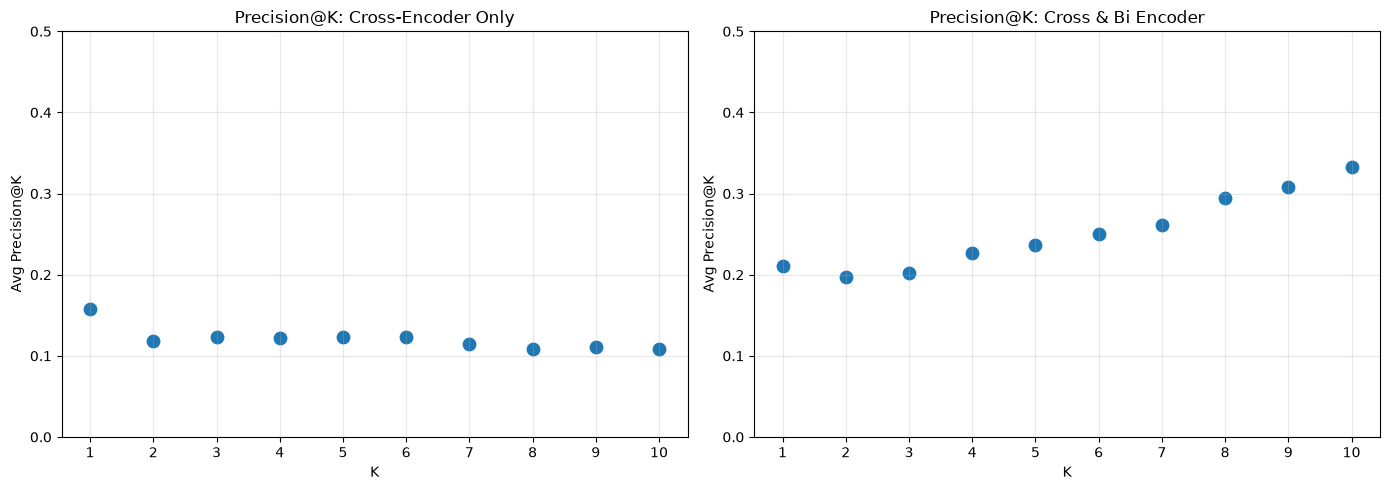

In [339]:
cross_prec_res = precision_res[precision_res["chunking_type"] == "cross_encoder_only"]
both_prec_res = precision_res[precision_res["chunking_type"] == "bi_cross"]

fig, axes = plt.subplots(nrows=1, ncols=2,figsize=(14, 5),sharey=True)

axes[0].scatter(cross_prec_res["k"], cross_prec_res["avg_precision"], s=80)
axes[0].set_title("Precision@K: Cross-Encoder Only")

axes[1].scatter(both_prec_res["k"], both_prec_res["avg_precision"], s=80)
axes[1].set_title("Precision@K: Cross & Bi Encoder")

for ax in axes:
    ax.set_xlabel("K")
    ax.set_ylabel("Avg Precision@K")
    ax.set_xticks(range(1, 11))
    ax.set_ylim(0, 0.5)
    ax.tick_params(axis="y", labelleft=True)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



On the graphs above, we can see that the avg precision is slowly dropping as k growing in the case where we use cross-encoder only for ranking the chunks. However, in the two-staged ranking - avg precision slighlty flactuates but  of course, the tendency is to drop as k grows.

In [340]:
def pooled_recall_at_k(combined_df, labels, k=10):
    results = []

    for question, group in combined_df.groupby("question"):
        top_k = group[group["rank"] <= k].sort_values("rank")

        if len(top_k) != k or top_k["true_relevance"].isna().any():
            continue
        pool = all_labels[all_labels["question"] == question]
        pool = pool[pool["relevancy"].isin([0, 1])]

        total_relevant = (pool["relevancy"] == 1).sum()
        if total_relevant == 0:
            continue

        retrieved_relevant = (top_k["true_relevance"] == 1).sum()
        recall = retrieved_relevant / total_relevant
        results.append({
            "question": question,
            "recall": recall
        })

    return pd.DataFrame(results)

In [341]:
recall_at_k_res = []

for c_type, chunks in chunk_types.items():
    for k in range(1, 11):
        avg_recall = np.mean(pooled_recall_at_k(chunks, labels, k)["recall"])

        recall_at_k_res.append({
            "chunking_type": c_type,
            "k": k,
            "avg_recall": avg_recall
        })

recall_at_k_res = pd.DataFrame(recall_at_k_res)
recall_at_k_res.to_csv("recall_at_k.csv", index=False)



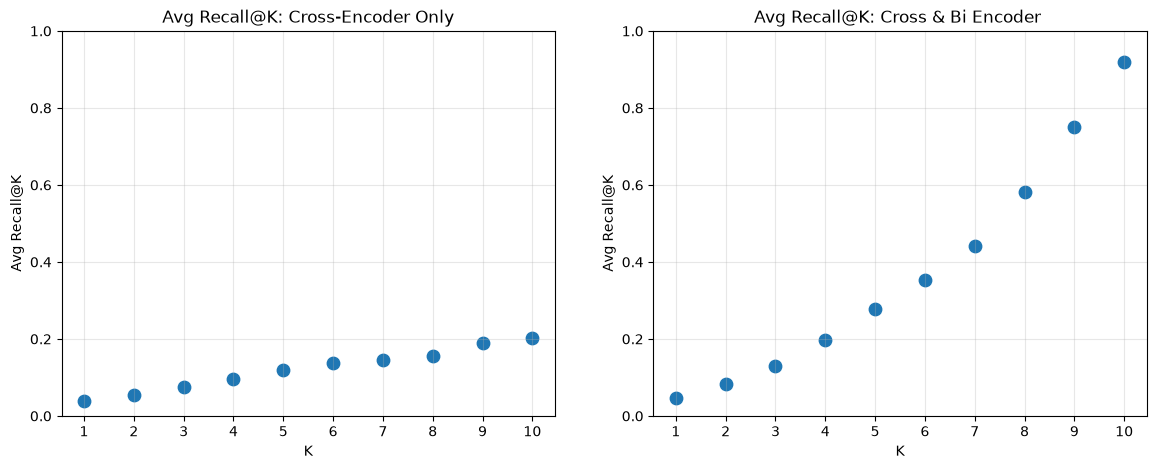

In [342]:
cross_rec_res = recall_at_k_res[recall_at_k_res["chunking_type"] == "cross_encoder_only"]
both_rec_res = recall_at_k_res[recall_at_k_res["chunking_type"] == "bi_cross"]

fig, axes = plt.subplots(nrows=1, ncols=2,figsize=(14, 5),sharey=True)

axes[0].scatter(cross_rec_res["k"], cross_rec_res["avg_recall"], s=80)
axes[0].set_title("Avg Recall@K: Cross-Encoder Only")

axes[1].scatter(both_rec_res["k"], both_rec_res["avg_recall"], s=80)
axes[1].set_title("Avg Recall@K: Cross & Bi Encoder ")

for ax in axes:
    ax.set_xlabel("K")
    ax.set_ylabel("Avg Recall@K")
    ax.set_xticks(range(1, 11))
    ax.set_ylim(0, 1)
    ax.tick_params(axis="y", labelleft=True)
    ax.grid(True, alpha=0.3)

In [343]:
def mrr_at_k(combined_df, k=10):
    results = []

    for question, group in combined_df.groupby("question"):
        top_k = group[group["rank"] <= k].sort_values("rank")
        if len(top_k) != k or top_k["true_relevance"].isna().any():
            continue
        relevant = top_k[
            top_k["true_relevance"] == 1
        ]

        if relevant.empty:
            reciprocal_rank = 0
        else:
            first_rank = relevant["rank"].iloc[0]
            reciprocal_rank = 1 / first_rank

        results.append({
            "question": question,
            "reciprocal_rank": reciprocal_rank
        })

    return pd.DataFrame(results)

In [344]:

mrr_at_k_res = []

for c_type, chunks in chunk_types.items():
    for k in range(1, 11):
        results = mrr_at_k(chunks, k)

        avg_mrr = (
            results["reciprocal_rank"].mean()
            if not results.empty
            else np.nan
        )

        mrr_at_k_res.append({
            "chunking_type": c_type,
            "k": k,
            "avg_mrr": avg_mrr,
            "evaluated_questions": len(results)
        })

mrr_df = pd.DataFrame(mrr_at_k_res)
mrr_df.to_csv("mrr_at_k.csv", index=False)

display(mrr_df.head(3))


,chunking_type,k,avg_mrr,evaluated_questions
0,cross_encoder_only,1,0.157895,76
1,cross_encoder_only,2,0.184211,76
2,cross_encoder_only,3,0.201754,76


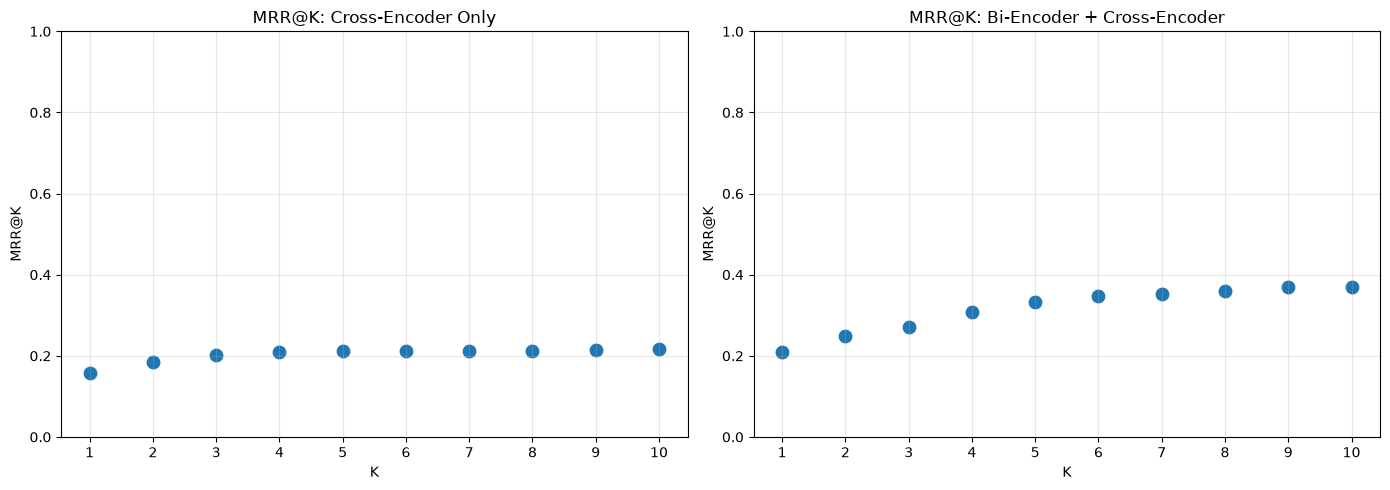

In [345]:
cross_mrr_res = mrr_df[mrr_df["chunking_type"] == "cross_encoder_only"]
both_mrr_res = mrr_df[mrr_df["chunking_type"] == "bi_cross"]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5), sharey=True)

axes[0].scatter(cross_mrr_res["k"], cross_mrr_res["avg_mrr"], s=80)
axes[0].set_title("MRR@K: Cross-Encoder Only")

axes[1].scatter(both_mrr_res["k"], both_mrr_res["avg_mrr"], s=80)
axes[1].set_title("MRR@K: Bi-Encoder + Cross-Encoder")

for ax in axes:
    ax.set_xlabel("K")
    ax.set_ylabel("MRR@K")
    ax.set_xticks(range(1, 11))
    ax.set_ylim(0, 1)
    ax.tick_params(axis="y", labelleft=True)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


We see that for the two-stages retrieval MRR at k=10 is closer to 0.4 which means on avarage the most relevant task is either on position ~2 or ~3. And at the same k=10, on avg the cross-encoder only model places the most relevant chunk at position ~5.

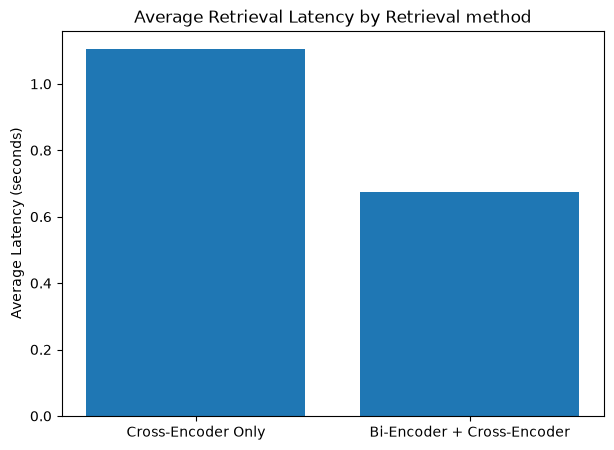

In [351]:

latencies_results = test_data[["sem_latency", "two_stage_latency"]].mean()
plt.figure(figsize=(7, 5))
plt.bar(["Cross-Encoder Only", "Bi-Encoder + Cross-Encoder"], latencies_results.values)

plt.ylabel("Average Latency (seconds)")
plt.title("Average Retrieval Latency by Retrieval method")
plt.show()

The two-stage retrieval pipeline demonstrates significantly lower latency, as expected. This improvement is primarily due to the faster bi-encoder efficiently filtering candidate chunks, allowing the more computationally expensive cross-encoder to process only a smaller subset.

**The take away:** I will use two-stage retrieval process for my project, as it showed slightly better results on precision, recall and mrr and latency.